In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import islice
from matplotlib.ticker import StrMethodFormatter


In [2]:

exp_data_file = pd.read_excel("Experimental_Data_All.xlsx" , sheet_name='Experimental_TC_data')


In [3]:

Exp_TC_comp_R134a = exp_data_file.iloc[0:9, 1]
Exp_TC_volfrac_R134a = exp_data_file.iloc[0:9, 2]
Exp_TC_R134a = exp_data_file.iloc[0:9, 3]
Exp_TC_err_R134a = exp_data_file.iloc[0:9, 4]
Exp_TC_volfracerr_R134a = exp_data_file.iloc[0:9, 5]

Exp_TC_comp_R32 = exp_data_file.iloc[9:, 1]
Exp_TC_volfrac_R32 = exp_data_file.iloc[9:, 2]
Exp_TC_R32 = exp_data_file.iloc[9:, 3]
Exp_TC_err_R32 = exp_data_file.iloc[9:, 4]
Exp_TC_volfracerr_R32 = exp_data_file.iloc[9:, 5]


In [4]:
MD_labels = pd.read_excel("Experimental_Data_All.xlsx" , sheet_name='MD_labels')
MD_labels = MD_labels.values
MD_labels[0:3]

array([['pure_emimtfsi_nil_300_100'],
       ['R32_emimtfsi_160_480_293'],
       ['R32_emimtfsi_320_320_721']], dtype=object)

In [5]:

NEMD_TC = np.zeros(len(MD_labels))
NEMD_TC_err = np.zeros(len(MD_labels))
HFC_comp = np.zeros(len(MD_labels))

for i, label in enumerate(MD_labels.flatten()):
    num_hfc = label.split('_')[2]
    num_hfc = 0 if num_hfc == 'nil' else num_hfc
    num_hfc = int(num_hfc)
    num_il = label.split('_')[3]
    num_il = int(num_il)
    comp_hfc = num_hfc/(num_hfc + num_il)
    HFC_comp[i] = comp_hfc
    TC = np.loadtxt(f"kappa_value_{label}.txt")
    NEMD_TC[i] = TC
    TC_err = np.loadtxt(f"kappa_value_abserror_{label}.txt")
    NEMD_TC_err[i] = TC_err
    



In [6]:

MD_TC_comp_R32 = HFC_comp[0:7]
MD_TC_val_R32 = NEMD_TC[0:7]
MD_TC_err_R32 = NEMD_TC_err[0:7]

MD_TC_comp_R134a = HFC_comp[7:]
MD_TC_val_R134a = NEMD_TC[7:]
MD_TC_err_R134a = NEMD_TC_err[7:]


In [7]:
MD_TC_val_R134a

array([177.83772652, 166.3955353 , 162.12463239, 153.80261448,
       140.21729796, 128.8788763 ,  96.28046918])

In [8]:
MD_TC_val_R32

array([177.83772652, 171.25331962, 168.38857922, 165.90876203,
       149.20626833, 117.2338472 ,  97.76713953])

In [9]:

def compute_excessTC(x_comp, TC_mix, TC_pureIL, TC_pureHFC):
    excessTC = TC_mix - (x_comp*TC_pureHFC + (1-x_comp)*TC_pureIL)
    return excessTC


def compute_excessTC_volfrac_error(x_comp, TC_pureIL, TC_pureHFC, err_x_comp, err_TC_mix, err_TC_pureIL, err_TC_pureHFC):
    err_excess_TC = err_TC_mix + np.abs(TC_pureIL - TC_pureHFC)*err_x_comp + x_comp*err_TC_pureHFC + np.abs(1-x_comp)*err_TC_pureIL
    return err_excess_TC


def compute_excessTC_molfrac_error(x_comp, TC_pureIL, TC_pureHFC, err_TC_mix, err_TC_pureIL, err_TC_pureHFC):
    err_excess_TC = err_TC_mix + x_comp*err_TC_pureHFC + np.abs(1-x_comp)*err_TC_pureIL
    return err_excess_TC



In [10]:
#Exp_TC_R134a

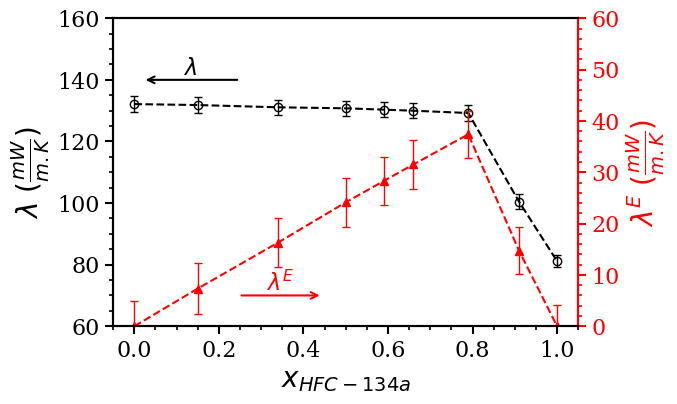

In [11]:

plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 1.5
})

fig, ax1 = plt.subplots(figsize=(6, 4))

Exp_excessTC_R134a_mol = compute_excessTC(Exp_TC_comp_R134a, Exp_TC_R134a, Exp_TC_R134a.iloc[0], Exp_TC_R134a.iloc[-1])
Exp_excessTC_R134a_mol_err = compute_excessTC_molfrac_error(Exp_TC_comp_R134a, Exp_TC_R134a.iloc[0], Exp_TC_R134a.iloc[-1], \
                                                            Exp_TC_err_R134a, Exp_TC_err_R134a.iloc[0], Exp_TC_err_R134a.iloc[-1])
                                                    

line1 = ax1.errorbar(Exp_TC_comp_R134a, Exp_TC_R134a, yerr = Exp_TC_err_R134a, ls='--' ,  ecolor = 'black', color='black', elinewidth=1, marker="o", markerfacecolor='none', markeredgecolor='black', capsize=3) #fmt='o',

ax1.minorticks_on()

ax1.set_xlabel(r'$x_{HFC-134a}$', fontsize=20)
ax1.set_ylabel(r'$\lambda$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20)
ax1.tick_params(axis='y', which='major', length=6, width=1.5, labelsize=16)
ax1.tick_params(axis='y', which='minor', length=3, width=1.2)
ax1.tick_params(axis='x', which='major', length=6, width=1.5, labelsize=16)
ax1.tick_params(axis='x', which='minor', length=3, width=1.2)
ax1.xaxis.set_major_formatter(StrMethodFormatter('{x:.1f}'))
ax1.set_ylim(60, 160)




ax1.annotate(
    '',                           # arrow
    xy=(0.02, 140),               # arrow head (near the left axis)
    xytext=(0.25, 140),           # arrow tail (toward the curve)
    arrowprops=dict(arrowstyle='->', lw=1.5, color='black')
)

ax1.text(
    0.135, 140,                 
    r'$\lambda$',
    ha='center',
    va='bottom',
    fontsize=16,
    color='black'
)


ax2 = ax1.twinx()

line2 = ax2.errorbar(Exp_TC_comp_R134a, Exp_excessTC_R134a_mol, yerr = Exp_excessTC_R134a_mol_err, ls='--' ,  ecolor = 'red', color='red', elinewidth=1, marker="^", markerfacecolor='red', markeredgecolor='red', capsize=3) 
#ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", ncol=3, fontsize=12.5)



ax2.minorticks_on()
ax2.set_ylabel(r'$\lambda^E$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20, color='red')
ax2.tick_params(axis='y', which='major',
                length=6, width=1.5,
                colors='red', labelsize=16)

ax2.tick_params(axis='y', which='minor',
                length=3, width=1.2,
                colors='red')
ax2.spines['right'].set_color('red')
ax2.set_ylim(0, 60)



ax2.annotate(
    '',
    xy=(0.45, 0.10),          
    xytext=(0.27, 0.10),      
    xycoords='axes fraction',
    textcoords='axes fraction',
    arrowprops=dict(arrowstyle='->', lw=1.5, color='red')
)

ax2.text(
    0.36, 0.10,              
    r'$\lambda^E$',
    transform=ax2.transAxes,
    ha='center',
    va='bottom',
    fontsize=16,
    color='red'
)


plt.savefig("TC_vs_molfrac_R134a_Exp_New_TCexcess", dpi=300, bbox_inches='tight')




In [12]:
print(Exp_excessTC_R32_mol_err, Exp_excessTC_R134a_mol_err)

NameError: name 'Exp_excessTC_R32_mol_err' is not defined

In [ ]:

plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 1.5
})

fig, ax1 = plt.subplots(figsize=(6, 4))

Exp_excessTC_R32_mol = compute_excessTC(Exp_TC_comp_R32, Exp_TC_R32, Exp_TC_R32.iloc[0], Exp_TC_R32.iloc[-1])
Exp_excessTC_R32_mol_err = compute_excessTC_molfrac_error(Exp_TC_comp_R32, Exp_TC_R32.iloc[0], Exp_TC_R32.iloc[-1], \
                                                            Exp_TC_err_R32, Exp_TC_err_R32.iloc[0], Exp_TC_err_R32.iloc[-1])
                                                    

line1 = ax1.errorbar(Exp_TC_comp_R32, Exp_TC_R32, yerr = Exp_TC_err_R32, ls='--' ,  ecolor = 'black', color='black', elinewidth=1, marker="o", markerfacecolor='none', markeredgecolor='black', capsize=3) #fmt='o',
line11 = ax1.errorbar(Exp_TC_comp_R32[5:7], Exp_TC_R32[5:7], yerr = Exp_TC_err_R32[5:7], ls='--' ,  ecolor = 'black', color='black', elinewidth=0.001, marker="o", markerfacecolor='black', markeredgecolor='black', capsize=0.003) #fmt='o',


ax1.minorticks_on()

ax1.set_xlabel(r'$x_{HFC-32}$', fontsize=20)
ax1.set_ylabel(r'$\lambda$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20)
ax1.tick_params(axis='y', which='major', length=6, width=1.5, labelsize=16)
ax1.tick_params(axis='y', which='minor', length=3, width=1.2)
ax1.tick_params(axis='x', which='major', length=6, width=1.5, labelsize=16)
ax1.tick_params(axis='x', which='minor', length=3, width=1.2)
ax1.xaxis.set_major_formatter(StrMethodFormatter('{x:.1f}'))
ax1.set_ylim(120, 140)




ax1.annotate(
    '',                           # arrow
    xy=(0.02, 135),               # arrow head (near the left axis)
    xytext=(0.25, 135),           # arrow tail (toward the curve)
    arrowprops=dict(arrowstyle='->', lw=1.5, color='black')
)

ax1.text(
    0.135, 135,                 
    r'$\lambda$',
    ha='center',
    va='bottom',
    fontsize=16,
    color='black'
)



ax2 = ax1.twinx()

line2 = ax2.errorbar(Exp_TC_comp_R32, Exp_excessTC_R32_mol, yerr = Exp_excessTC_R32_mol_err, ls='--' ,  ecolor = 'red', color='red', elinewidth=1, marker="^", markerfacecolor='red', markeredgecolor='red', capsize=3) 
#ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", ncol=3, fontsize=12.5)



ax2.minorticks_on()
ax2.set_ylabel(r'$\lambda^E$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20, color='red')
ax2.tick_params(axis='y', which='major',
                length=6, width=1.5,
                colors='red', labelsize=16)

ax2.tick_params(axis='y', which='minor',
                length=3, width=1.2,
                colors='red')
ax2.spines['right'].set_color('red')
ax2.yaxis.set_major_formatter(StrMethodFormatter('{x:.0f}'))
ax2.set_ylim(0, 15)



ax2.annotate(
    '',
    xy=(0.52, 0.05),         # Increased x (0.45 -> 0.50), decreased y (0.10 -> 0.05)
    xytext=(0.34, 0.05),     # Increased x (0.27 -> 0.32), decreased y (0.10 -> 0.05)
    xycoords='axes fraction',
    textcoords='axes fraction',
    arrowprops=dict(arrowstyle='->', lw=1.5, color='red')
)

ax2.text(
    0.42, 0.05,              # Match the new arrow tip position (x=0.50, y=0.05)
    r'$\lambda^E$',
    transform=ax2.transAxes,
    ha='center',
    va='bottom',
    fontsize=16,
    color='red'
)


plt.savefig("TC_vs_molfrac_R32_Exp_New_TCexcess", dpi=300, bbox_inches='tight')




Text(0.35, 0.12, '$\\lambda^E$')

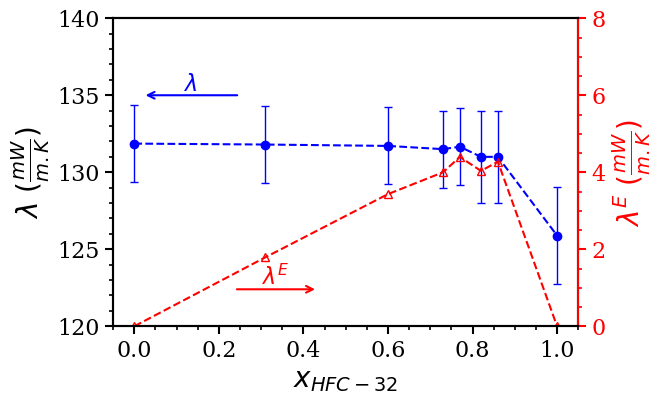

In [32]:


plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 1.5
})

fig, ax1 = plt.subplots(figsize=(6, 4))

Exp_excessTC_R32_mol = compute_excessTC(Exp_TC_comp_R32, Exp_TC_R32, Exp_TC_R32.iloc[0], Exp_TC_R32.iloc[-1])


line1 = ax1.errorbar(Exp_TC_comp_R32, Exp_TC_R32, yerr = Exp_TC_err_R32, fmt='o--', ecolor = 'blue', color='blue', elinewidth=1, label = 'Experiment', capsize=3) #fmt='o',

ax1.minorticks_on()

ax1.set_xlabel(r'$x_{HFC-32}$', fontsize=20)
ax1.set_ylabel(r'$\lambda$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20)
ax1.tick_params(axis='y', which='major', length=6, width=1.5, labelsize=16)
ax1.tick_params(axis='y', which='minor', length=3, width=1.2)
ax1.tick_params(axis='x', which='major', length=6, width=1.5, labelsize=16)
ax1.tick_params(axis='x', which='minor', length=3, width=1.2)
ax1.xaxis.set_major_formatter(StrMethodFormatter('{x:.1f}'))
ax1.set_ylim(120, 140)

ax1.annotate(
    '',                           # arrow
    xy=(0.02, 135),               # arrow head (near the left axis)
    xytext=(0.25, 135),           # arrow tail (toward the curve)
    arrowprops=dict(arrowstyle='->', lw=1.5, color='blue')
)

ax1.text(
    0.135, 135,                 
    r'$\lambda$',
    ha='center',
    va='bottom',
    fontsize=16,
    color='blue'
)


ax2 = ax1.twinx()

line2, = ax2.plot(Exp_TC_comp_R32, Exp_excessTC_R32_mol, ls='--' , color='red', marker="^", markerfacecolor='none', markeredgecolor='red') #fmt='o',
#ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", ncol=3, fontsize=12.5)



ax2.minorticks_on()
ax2.set_ylabel(r'$\lambda^E$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20, color='red')
ax2.tick_params(axis='y', which='major',
                length=6, width=1.5,
                colors='red', labelsize=16)

ax2.tick_params(axis='y', which='minor',
                length=3, width=1.2,
                colors='red')
ax2.spines['right'].set_color('red')
ax2.set_ylim(0, 8)



ax2.annotate(
    '',
    xy=(0.44, 0.12),          
    xytext=(0.26, 0.12),      
    xycoords='axes fraction',
    textcoords='axes fraction',
    arrowprops=dict(arrowstyle='->', lw=1.5, color='red')
)

ax2.text(
    0.35, 0.12,              
    r'$\lambda^E$',
    transform=ax2.transAxes,
    ha='center',
    va='bottom',
    fontsize=16,
    color='red'
)


#plt.savefig("TC_vs_molfrac_R32_Exp_New_TCexcess", dpi=300, bbox_inches='tight')




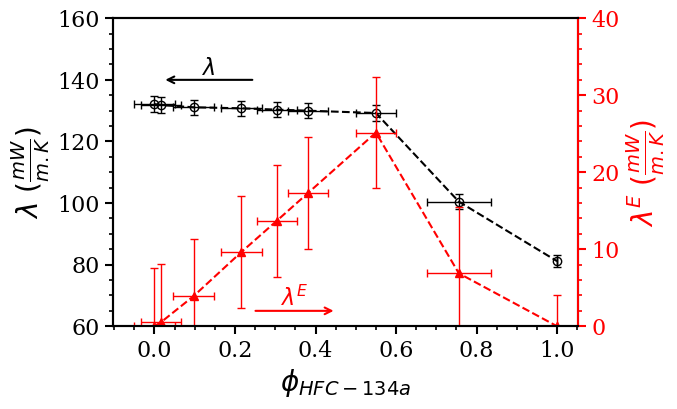

In [13]:

plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 1.5
})

fig, ax1 = plt.subplots(figsize=(6, 4))

Exp_excessTC_R134a_vol = compute_excessTC(Exp_TC_volfrac_R134a, Exp_TC_R134a, Exp_TC_R134a.iloc[0], Exp_TC_R134a.iloc[-1])
Exp_excessTC_R134a_vol_err = compute_excessTC_volfrac_error(Exp_TC_comp_R134a, Exp_TC_R134a.iloc[0], Exp_TC_R134a.iloc[-1], Exp_TC_volfracerr_R134a, \
                                                            Exp_TC_err_R134a, Exp_TC_err_R134a.iloc[0], Exp_TC_err_R134a.iloc[-1])

#compute_excessTC_volfrac_error(x_comp, TC_pureIL, TC_pureHFC, err_x_comp, err_TC_mix, err_TC_pureIL, err_TC_pureHFC)



line1 = ax1.errorbar(Exp_TC_volfrac_R134a, Exp_TC_R134a, xerr = Exp_TC_volfracerr_R134a, yerr = Exp_TC_err_R134a, fmt='o--', ecolor = 'black', color='black', markerfacecolor='none', markeredgecolor='black', elinewidth=1, capsize=3) #fmt='o',

ax1.minorticks_on()

ax1.set_xlabel(r'$\phi_{HFC-134a}$', fontsize=20)
ax1.set_ylabel(r'$\lambda$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20)
ax1.tick_params(axis='y', which='major', length=6, width=1.5, labelsize=16)
ax1.tick_params(axis='y', which='minor', length=3, width=1.2)
ax1.tick_params(axis='x', which='major', length=6, width=1.5, labelsize=16)
ax1.tick_params(axis='x', which='minor', length=3, width=1.2)
ax1.xaxis.set_major_formatter(StrMethodFormatter('{x:.1f}'))
ax1.set_ylim(60, 160)




ax1.annotate(
    '',                           # arrow
    xy=(0.02, 140),               # arrow head (near the left axis)
    xytext=(0.25, 140),           # arrow tail (toward the curve)
    arrowprops=dict(arrowstyle='->', lw=1.5, color='black')
)

ax1.text(
    0.135, 140,                 
    r'$\lambda$',
    ha='center',
    va='bottom',
    fontsize=16,
    color='black'
)


ax2 = ax1.twinx()

#line2, = ax2.plot(Exp_TC_volfrac_R134a, Exp_excessTC_R134a_vol, ls='--' , color='red', marker="s", markerfacecolor='none', markeredgecolor='red') #fmt='o',
#ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", ncol=3, fontsize=12.5)

line2 = ax2.errorbar(Exp_TC_volfrac_R134a, Exp_excessTC_R134a_vol, xerr = Exp_TC_volfracerr_R134a, yerr = Exp_excessTC_R134a_vol_err, fmt='^--', ecolor = 'red', color='red', markerfacecolor='red', markeredgecolor='red', elinewidth=1, capsize=3) #fmt='o',


ax2.minorticks_on()
ax2.set_ylabel(r'$\lambda^E$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20, color='red')
ax2.tick_params(axis='y', which='major',
                length=6, width=1.5,
                colors='red', labelsize=16)

ax2.tick_params(axis='y', which='minor',
                length=3, width=1.2,
                colors='red')
ax2.spines['right'].set_color('red')
ax2.set_ylim(0, 40)



ax2.annotate(
    '',
    xy=(0.48, 0.05),          
    xytext=(0.30, 0.05),      
    xycoords='axes fraction',
    textcoords='axes fraction',
    arrowprops=dict(arrowstyle='->', lw=1.5, color='red')
)

ax2.text(
    0.39, 0.05,              
    r'$\lambda^E$',
    transform=ax2.transAxes,
    ha='center',
    va='bottom',
    fontsize=16,
    color='red'
)


plt.savefig("TC_vs_volfrac_R134a_Exp_New_TCexcess", dpi=300, bbox_inches='tight')




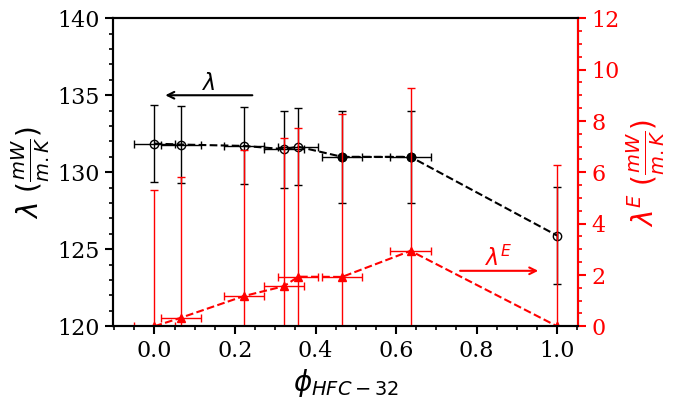

In [14]:

plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 1.5
})

fig, ax1 = plt.subplots(figsize=(6, 4))

Exp_excessTC_R32_vol = compute_excessTC(Exp_TC_volfrac_R32, Exp_TC_R32, Exp_TC_R32.iloc[0], Exp_TC_R32.iloc[-1])
Exp_excessTC_R32_vol_err = compute_excessTC_volfrac_error(Exp_TC_comp_R32, Exp_TC_R32.iloc[0], Exp_TC_R32.iloc[-1], Exp_TC_volfracerr_R32, \
                                                            Exp_TC_err_R32, Exp_TC_err_R32.iloc[0], Exp_TC_err_R32.iloc[-1])

#compute_excessTC_volfrac_error(x_comp, TC_pureIL, TC_pureHFC, err_x_comp, err_TC_mix, err_TC_pureIL, err_TC_pureHFC)



line1 = ax1.errorbar(Exp_TC_volfrac_R32, Exp_TC_R32, xerr = Exp_TC_volfracerr_R32, yerr = Exp_TC_err_R32, fmt='o--', ecolor = 'black', color='black', markerfacecolor='none', markeredgecolor='black', elinewidth=1, capsize=3) #fmt='o',
line11 = ax1.errorbar(Exp_TC_volfrac_R32[5:7], Exp_TC_R32[5:7], xerr = Exp_TC_volfracerr_R32[5:7], yerr = Exp_TC_err_R32[5:7], fmt='o--', ecolor = 'black', color='black', markerfacecolor='black', markeredgecolor='black', elinewidth=0.001, capsize=0.003) #fmt='o',

ax1.minorticks_on()

ax1.set_xlabel(r'$\phi_{HFC-32}$', fontsize=20)
ax1.set_ylabel(r'$\lambda$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20)
ax1.tick_params(axis='y', which='major', length=6, width=1.5, labelsize=16)
ax1.tick_params(axis='y', which='minor', length=3, width=1.2)
ax1.tick_params(axis='x', which='major', length=6, width=1.5, labelsize=16)
ax1.tick_params(axis='x', which='minor', length=3, width=1.2)
ax1.xaxis.set_major_formatter(StrMethodFormatter('{x:.1f}'))
ax1.set_ylim(120, 140)




ax1.annotate(
    '',                           # arrow
    xy=(0.02, 135),               # arrow head (near the left axis)
    xytext=(0.25, 135),           # arrow tail (toward the curve)
    arrowprops=dict(arrowstyle='->', lw=1.5, color='black')
)

ax1.text(
    0.135, 135,                 
    r'$\lambda$',
    ha='center',
    va='bottom',
    fontsize=16,
    color='black'
)


ax2 = ax1.twinx()

#line2, = ax2.plot(Exp_TC_volfrac_R32, Exp_excessTC_R32_vol, ls='--' , color='red', marker="s", markerfacecolor='none', markeredgecolor='red') #fmt='o',
#ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", ncol=3, fontsize=12.5)

line2 = ax2.errorbar(Exp_TC_volfrac_R32, Exp_excessTC_R32_vol, xerr = Exp_TC_volfracerr_R32, yerr = Exp_excessTC_R32_vol_err, fmt='^--', ecolor = 'red', color='red', markerfacecolor='red', markeredgecolor='red', elinewidth=1, capsize=3) #fmt='o',


ax2.minorticks_on()
ax2.set_ylabel(r'$\lambda^E$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20, color='red')
ax2.tick_params(axis='y', which='major',
                length=6, width=1.5,
                colors='red', labelsize=16)

ax2.tick_params(axis='y', which='minor',
                length=3, width=1.2,
                colors='red')
ax2.spines['right'].set_color('red')
ax2.set_ylim(0, 12)



ax2.annotate(
    '',
    xy=(0.92, 0.18),          
    xytext=(0.74, 0.18),      
    xycoords='axes fraction',
    textcoords='axes fraction',
    arrowprops=dict(arrowstyle='->', lw=1.5, color='red')
)

ax2.text(
    0.83, 0.18,              
    r'$\lambda^E$',
    transform=ax2.transAxes,
    ha='center',
    va='bottom',
    fontsize=16,
    color='red'
)


plt.savefig("TC_vs_volfrac_R32_Exp_New_TCexcess", dpi=300, bbox_inches='tight')




Text(0.36, 0.12, '$\\lambda^E$')

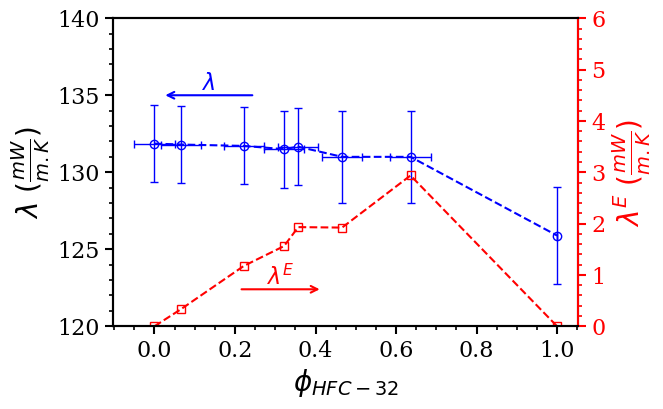

In [15]:

plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 1.5
})

fig, ax1 = plt.subplots(figsize=(6, 4))

Exp_excessTC_R32_vol = compute_excessTC(Exp_TC_volfrac_R32, Exp_TC_R32, Exp_TC_R32.iloc[0], Exp_TC_R32.iloc[-1])


line1 = ax1.errorbar(Exp_TC_volfrac_R32, Exp_TC_R32, xerr = Exp_TC_volfracerr_R32, yerr = Exp_TC_err_R32, fmt='o--', ecolor = 'blue',color='blue',  markerfacecolor='none', markeredgecolor='blue', elinewidth=1, label = 'Experiment', capsize=3) #fmt='o',

ax1.minorticks_on()

ax1.set_xlabel(r'$\phi_{HFC-32}$', fontsize=20)
ax1.set_ylabel(r'$\lambda$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20)
ax1.tick_params(axis='y', which='major', length=6, width=1.5, labelsize=16)
ax1.tick_params(axis='y', which='minor', length=3, width=1.2)
ax1.tick_params(axis='x', which='major', length=6, width=1.5, labelsize=16)
ax1.tick_params(axis='x', which='minor', length=3, width=1.2)
ax1.xaxis.set_major_formatter(StrMethodFormatter('{x:.1f}'))
ax1.set_ylim(120, 140)




ax1.annotate(
    '',                           # arrow
    xy=(0.02, 135),               # arrow head (near the left axis)
    xytext=(0.25, 135),           # arrow tail (toward the curve)
    arrowprops=dict(arrowstyle='->', lw=1.5, color='blue')
)

ax1.text(
    0.135, 135,                 
    r'$\lambda$',
    ha='center',
    va='bottom',
    fontsize=16,
    color='blue'
)


ax2 = ax1.twinx()

line2, = ax2.plot(Exp_TC_volfrac_R32, Exp_excessTC_R32_vol, ls='--' , color='red', marker="s", markerfacecolor='none', markeredgecolor='red') #fmt='o',
#ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", ncol=3, fontsize=12.5)



ax2.minorticks_on()
ax2.set_ylabel(r'$\lambda^E$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20, color='red')
ax2.tick_params(axis='y', which='major',
                length=6, width=1.5,
                colors='red', labelsize=16)

ax2.tick_params(axis='y', which='minor',
                length=3, width=1.2,
                colors='red')
ax2.spines['right'].set_color('red')
ax2.set_ylim(0, 6)



ax2.annotate(
    '',
    xy=(0.45, 0.12),          
    xytext=(0.27, 0.12),      
    xycoords='axes fraction',
    textcoords='axes fraction',
    arrowprops=dict(arrowstyle='->', lw=1.5, color='red')
)

ax2.text(
    0.36, 0.12,              
    r'$\lambda^E$',
    transform=ax2.transAxes,
    ha='center',
    va='bottom',
    fontsize=16,
    color='red'
)


#plt.savefig("TC_vs_volfrac_R32_Exp_New_TCexcess", dpi=300, bbox_inches='tight')




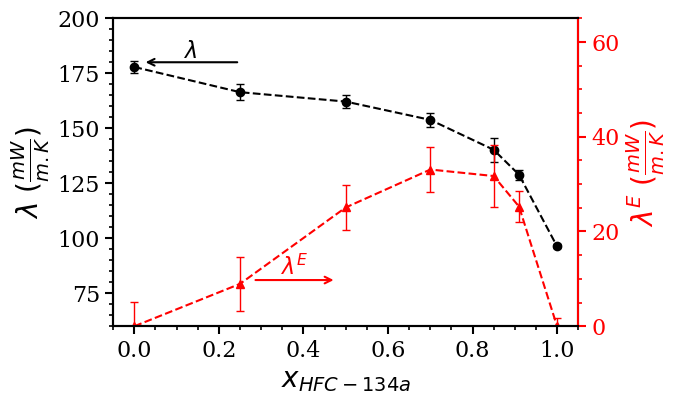

In [16]:

plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 1.5
})

fig, ax1 = plt.subplots(figsize=(6, 4))

MD_excessTC_R134a_mol = compute_excessTC(MD_TC_comp_R134a, MD_TC_val_R134a, MD_TC_val_R134a[0], MD_TC_val_R134a[-1])
MD_excessTC_R134a_mol_err = compute_excessTC_molfrac_error(MD_TC_comp_R134a, MD_TC_val_R134a[0], MD_TC_val_R134a[-1], \
                                                            MD_TC_err_R134a, MD_TC_err_R134a[0], MD_TC_err_R134a[-1])

line1 = ax1.errorbar(MD_TC_comp_R134a, MD_TC_val_R134a, yerr = MD_TC_err_R134a, fmt='o--', ecolor = 'black', color='black', elinewidth=1, capsize=3) #fmt='o',

ax1.minorticks_on()

ax1.set_xlabel(r'$x_{HFC-134a}$', fontsize=20)
ax1.set_ylabel(r'$\lambda$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20)
ax1.tick_params(axis='y', which='major', length=6, width=1.5, labelsize=16)
ax1.tick_params(axis='y', which='minor', length=3, width=1.2)
ax1.tick_params(axis='x', which='major', length=6, width=1.5, labelsize=16)
ax1.tick_params(axis='x', which='minor', length=3, width=1.2)
ax1.xaxis.set_major_formatter(StrMethodFormatter('{x:.1f}'))
ax1.set_ylim(60, 200)




ax1.annotate(
    '',                           # arrow
    xy=(0.02, 180),               # arrow head (near the left axis)
    xytext=(0.25, 180),           # arrow tail (toward the curve)
    arrowprops=dict(arrowstyle='->', lw=1.5, color='black')
)

ax1.text(
    0.135, 180,                 
    r'$\lambda$',
    ha='center',
    va='bottom',
    fontsize=16,
    color='black'
)


ax2 = ax1.twinx()

#line2, = ax2.plot(MD_TC_comp_R134a, MD_excessTC_R134a_mol, ls='--' , color='red', marker="^", markerfacecolor='none', markeredgecolor='red') #fmt='o',
#ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", ncol=3, fontsize=12.5)
line2 = ax2.errorbar(MD_TC_comp_R134a, MD_excessTC_R134a_mol, yerr = MD_excessTC_R134a_mol_err, fmt='^--', ecolor = 'red', color='red', elinewidth=1, capsize=3)


ax2.minorticks_on()
ax2.set_ylabel(r'$\lambda^E$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20, color='red')
ax2.tick_params(axis='y', which='major',
                length=6, width=1.5,
                colors='red', labelsize=16)

ax2.tick_params(axis='y', which='minor',
                length=3, width=1.2,
                colors='red')
ax2.spines['right'].set_color('red')
ax2.set_ylim(0, 65)



ax2.annotate(
    '',
    xy=(0.48, 0.15),          
    xytext=(0.30, 0.15),      
    xycoords='axes fraction',
    textcoords='axes fraction',
    arrowprops=dict(arrowstyle='->', lw=1.5, color='red')
)

ax2.text(
    0.39, 0.15,              
    r'$\lambda^E$',
    transform=ax2.transAxes,
    ha='center',
    va='bottom',
    fontsize=16,
    color='red'
)


plt.savefig("TC_vs_molfrac_R134a_MD_New_TCexcess", dpi=300, bbox_inches='tight')




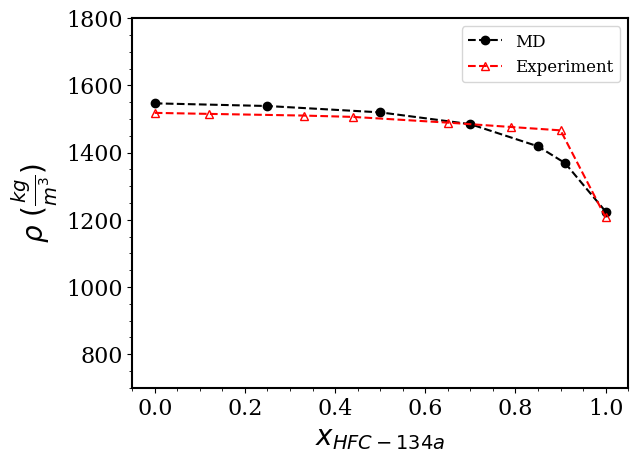

In [22]:
fig, ax = plt.subplots()

R134a_IL_MD_density = np.array([1.546382535846428929e+00, 1.538419472324310311e+00, \
                    1.519551839726672959e+00, 1.484379013465555452e+00, \
                    1.418414779625282396e+00, 1.368555864817189160e+00, 1.224261167873839762e+00])*1000
R134a_IL_MD_dens_comp = MD_TC_comp_R134a

R134a_IL_Exp_density = np.array([1518, 1515, 1510, 1506, 1489, 1476, 1466, 1206.7])
R134a_IL_Exp_comp = np.array([0.0, 0.12, 0.33, 0.44, 0.65, 0.79, 0.90, 1.00])                                


plt.plot(R134a_IL_MD_dens_comp, R134a_IL_MD_density, ls='--' , color='black', marker="o", markerfacecolor='black', markeredgecolor='black', label = 'MD')
plt.plot(R134a_IL_Exp_comp, R134a_IL_Exp_density, ls='--' , color='red', marker="^", markerfacecolor='none', markeredgecolor='red', label = 'Experiment')

plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
ax.minorticks_on()
plt.ylabel(r'$\rho$' ' ' r'$(\frac{kg}{m^3})$', fontsize=20)
plt.xlabel(r'$x_{HFC-134a}$', fontsize=20)
plt.ylim(700, 1800)
plt.legend()

plt.savefig("rho_vs_molfrac_MD_Exp_R134a", dpi=300, bbox_inches='tight')


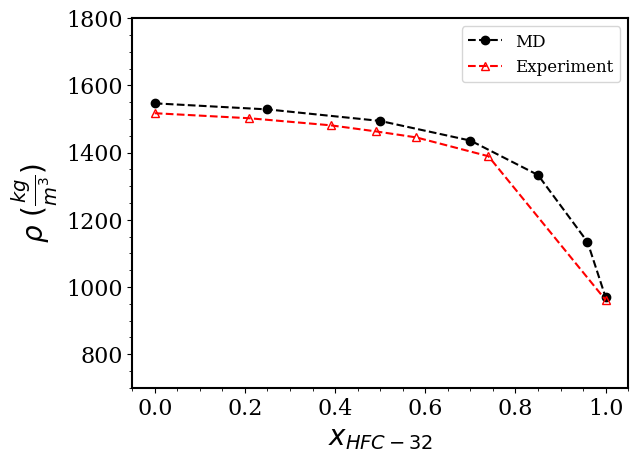

In [23]:

fig, ax = plt.subplots()

R32_IL_MD_density = np.array([1.546382535846428929e+00, 1.528350141094679815e+00, \
                    1.493999807268303615e+00, 1.435476471527121545e+00, \
                    1.333096501076322715e+00, 1.134018706308589142e+00, 9.687023016336407943e-01])*1000
R32_IL_MD_dens_comp = MD_TC_comp_R32

R32_IL_Exp_density = np.array([1517, 1502, 1481, 1463, 1445, 1389, 961.01])
R32_IL_Exp_comp = np.array([0.00, 0.21, 0.39, 0.49, 0.58, 0.74, 1.00])                                


plt.plot(R32_IL_MD_dens_comp, R32_IL_MD_density, ls='--' , color='black', marker="o", markerfacecolor='black', markeredgecolor='black', label = 'MD')
plt.plot(R32_IL_Exp_comp, R32_IL_Exp_density, ls='--' , color='red', marker="^", markerfacecolor='none', markeredgecolor='red', label = 'Experiment')

plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
ax.minorticks_on()
plt.ylabel(r'$\rho$' ' ' r'$(\frac{kg}{m^3})$', fontsize=20)
plt.xlabel(r'$x_{HFC-32}$', fontsize=20)
plt.ylim(700, 1800)
plt.legend()

plt.savefig("rho_vs_molfrac_MD_Exp_R32", dpi=300, bbox_inches='tight')


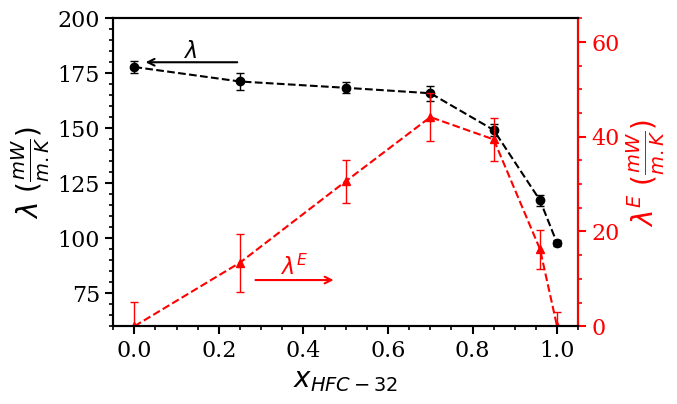

In [59]:

plt.rcParams.update({
    "text.usetex": False, 
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 1.5
})

fig, ax1 = plt.subplots(figsize=(6, 4))

MD_excessTC_R32_mol = compute_excessTC(MD_TC_comp_R32, MD_TC_val_R32, MD_TC_val_R32[0], MD_TC_val_R32[-1])
MD_excessTC_R32_mol_err = compute_excessTC_molfrac_error(MD_TC_comp_R32, MD_TC_val_R32[0], MD_TC_val_R32[-1], \
                                                            MD_TC_err_R32, MD_TC_err_R32[0], MD_TC_err_R32[-1])

line1 = ax1.errorbar(MD_TC_comp_R32, MD_TC_val_R32, yerr = MD_TC_err_R32, fmt='o--', ecolor = 'black', color='black', elinewidth=1, capsize=3) #fmt='o',

ax1.minorticks_on()

ax1.set_xlabel(r'$x_{HFC-32}$', fontsize=20)
ax1.set_ylabel(r'$\lambda$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20)
ax1.tick_params(axis='y', which='major', length=6, width=1.5, labelsize=16)
ax1.tick_params(axis='y', which='minor', length=3, width=1.2)
ax1.tick_params(axis='x', which='major', length=6, width=1.5, labelsize=16)
ax1.tick_params(axis='x', which='minor', length=3, width=1.2)
ax1.xaxis.set_major_formatter(StrMethodFormatter('{x:.1f}'))
ax1.set_ylim(60, 200)




ax1.annotate(
    '',                           # arrow
    xy=(0.02, 180),               # arrow head (near the left axis)
    xytext=(0.25, 180),           # arrow tail (toward the curve)
    arrowprops=dict(arrowstyle='->', lw=1.5, color='black')
)

ax1.text(
    0.135, 180,                 
    r'$\lambda$',
    ha='center',
    va='bottom',
    fontsize=16,
    color='black'
)


ax2 = ax1.twinx()

#line2, = ax2.plot(MD_TC_comp_R32, MD_excessTC_R32_mol, ls='--' , color='red', marker="^", markerfacecolor='none', markeredgecolor='red') #fmt='o',
#ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", ncol=3, fontsize=12.5)
line2 = ax2.errorbar(MD_TC_comp_R32, MD_excessTC_R32_mol, yerr = MD_excessTC_R32_mol_err, fmt='^--', ecolor = 'red', color='red', elinewidth=1, capsize=3)



ax2.minorticks_on()
ax2.set_ylabel(r'$\lambda^E$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20, color='red')
ax2.tick_params(axis='y', which='major',
                length=6, width=1.5,
                colors='red', labelsize=16)

ax2.tick_params(axis='y', which='minor',
                length=3, width=1.2,
                colors='red')
ax2.spines['right'].set_color('red')
ax2.set_ylim(0, 65)



ax2.annotate(
    '',
    xy=(0.48, 0.15),          
    xytext=(0.30, 0.15),      
    xycoords='axes fraction',
    textcoords='axes fraction',
    arrowprops=dict(arrowstyle='->', lw=1.5, color='red')
)

ax2.text(
    0.39, 0.15,              
    r'$\lambda^E$',
    transform=ax2.transAxes,
    ha='center',
    va='bottom',
    fontsize=16,
    color='red'
)


plt.savefig("TC_vs_molfrac_R32_MD_New_TCexcess", dpi=300, bbox_inches='tight')




In [16]:
# plt.rcParams.update({
#     "text.usetex": False, # Set to True if you have LaTeX installed
#     "font.family": "serif",
#     "font.size": 12,
#     "axes.linewidth": 1.5
# })


# fig, ax = plt.subplots()

# ax.errorbar(MD_TC_comp_R134a, MD_TC_val_R134a, yerr = MD_TC_err_R134a, fmt='D--',ecolor = 'gray',color='gray', label = 'HFC-134a', capsize=3)

# ax.errorbar(MD_TC_comp_R32, MD_TC_val_R32, yerr = MD_TC_err_R32, fmt='o--', ecolor = 'blue',color='blue', elinewidth=3, label = 'HFC-32', capsize=3) #fmt='o',
# ax.legend( loc="lower left", fontsize=14)
# plt.yticks(fontsize=16)
# plt.xticks(fontsize=16)
# ax.minorticks_on()
# plt.ylim(60, 200)
# plt.xlabel(r'$x_{HFC}$', fontsize=20)
# plt.ylabel(r'$\lambda$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20)

# plt.savefig("TC_vs_volfrac_MD", dpi=500, bbox_inches='tight')


In [17]:

def running_average(file):
  running_ave = np.zeros(( len(file[:,0]) , len(file[0,:]) ))
  for i in range(len(file[0,:])):
        for j in range(len(file[:,0])): 
            mov_average = np.mean(file[0:j+1,i])
            running_ave[j,i] = mov_average
  return(running_ave)


In [18]:

def extract_hfdcorr_data(input_df, ehex_id):
    
    mol_t = input_df.iloc[:, 0]
    mol_t = mol_t.to_numpy()

    mol_calibrate_time = mol_t[0]
    heatflux_decompose_time = open(f'avefluxes_one_ce_left.{mol_calibrate_time}_reshape_HFD.{ehex_id}.profile')
    ext_heatflux_time = []
    for line in heatflux_decompose_time:
        ext_heatflux_time_1 = ((line.split(' ')[0]))
        ext_heatflux_time = np.append(ext_heatflux_time, ext_heatflux_time_1)
    ext_heatflux_time = np.array(ext_heatflux_time)
    ext_heatflux_time = ext_heatflux_time[2:]
    ext_heatflux_time = ext_heatflux_time.astype(float)

    run_avg_start_index = int((len(ext_heatflux_time))/2)
    
    ext_heatflux_convective = np.zeros((run_avg_start_index, len(mol_t)))
    ext_heatflux_coulombic = np.zeros((run_avg_start_index, len(mol_t)))
    ext_heatflux_bond = np.zeros((run_avg_start_index, len(mol_t)))
    ext_heatflux_angle = np.zeros((run_avg_start_index, len(mol_t)))
    ext_heatflux_dihedral = np.zeros((run_avg_start_index, len(mol_t)))
    ext_heatflux_pair = np.zeros((run_avg_start_index, len(mol_t)))
    ext_heatflux_total = np.zeros((run_avg_start_index, len(mol_t)))
    ext_heatflux_imposed = np.zeros((run_avg_start_index, len(mol_t)))
    #-------------------- heat fluxes with centroid approach --------------
    ext_heatflux_ce_angle = np.zeros((run_avg_start_index, len(mol_t)))
    ext_heatflux_ce_bond = np.zeros((run_avg_start_index, len(mol_t)))
    ext_heatflux_ce_dihedral = np.zeros((run_avg_start_index, len(mol_t)))
    ext_heatflux_ce_pair = np.zeros((run_avg_start_index, len(mol_t)))

    scale_time_imp = 10
    ext_heatflux_ce_imp = np.zeros(( int(run_avg_start_index/scale_time_imp), len(mol_t)))
   

    for i in range(len(mol_t)):
        #print(mol_t[i])
        
        with open(f"avefluxes_one_left.{mol_t[i]}_reshape_HFD.{ehex_id}.profile") as file_1:
        
            heatflux_decompose_output = islice(file_1, 2, None)
            
            ext_heatflux_imposed_pertemp = []
            ext_heatflux_total_pertemp = []
            ext_heatflux_coulombic_pertemp = []
            ext_heatflux_convective_pertemp = []
            ext_heatflux_angle_pertemp = []
            ext_heatflux_bond_pertemp = []
            ext_heatflux_dihedral_pertemp = []
            ext_heatflux_pair_pertemp = []
            
            
            for line in heatflux_decompose_output:
                 
                ext_heatflux_imposed_1 = ((line.split()[8]))
                ext_heatflux_imposed_pertemp.append(float(ext_heatflux_imposed_1))
        
                ext_heatflux_total_1 = ((line.split()[7]))
                ext_heatflux_total_pertemp.append(float(ext_heatflux_total_1))
        
                ext_heatflux_coulombic_1 = ((line.split()[6]))
                ext_heatflux_coulombic_pertemp.append(float(ext_heatflux_coulombic_1))
        
                ext_heatflux_convective_1 = ((line.split()[1]))
                ext_heatflux_convective_pertemp.append(float(ext_heatflux_convective_1))
                
                ext_heatflux_angle_1 = ((line.split()[2]))
                ext_heatflux_angle_pertemp.append(float(ext_heatflux_angle_1))
                
                ext_heatflux_bond_1 = ((line.split()[3]))
                ext_heatflux_bond_pertemp.append(float(ext_heatflux_bond_1))
                
                ext_heatflux_dihedral_1 = ((line.split()[4]))
                ext_heatflux_dihedral_pertemp.append(float(ext_heatflux_dihedral_1))
                
                ext_heatflux_pair_1 = ((line.split()[5]))
                ext_heatflux_pair_pertemp.append(float(ext_heatflux_pair_1))
        
        
        with open(f"avefluxes_one_ce_left.{mol_t[i]}_reshape_HFD.{ehex_id}.profile") as file_2:
        
            heatflux_decompose_output_ce = islice(file_2, 2, None)
            
            ext_heatflux_ce_angle_pertemp = []
            ext_heatflux_ce_bond_pertemp = []
            ext_heatflux_ce_dihedral_pertemp = []
            ext_heatflux_ce_pair_pertemp = []
            
            for line in heatflux_decompose_output_ce:
                 
                ext_heatflux_ce_pair_1 = ((line.split()[-2]))
                ext_heatflux_ce_pair_pertemp.append(float(ext_heatflux_ce_pair_1))
        
                ext_heatflux_ce_dihedral_1 = ((line.split()[-3]))
                ext_heatflux_ce_dihedral_pertemp.append(float(ext_heatflux_ce_dihedral_1))
        
                ext_heatflux_ce_bond_1 = ((line.split()[-4]))
                ext_heatflux_ce_bond_pertemp.append(float(ext_heatflux_ce_bond_1))
        
                ext_heatflux_ce_angle_1 = ((line.split()[-5]))
                ext_heatflux_ce_angle_pertemp.append(float(ext_heatflux_ce_angle_1))

        with open(f"avefluxes_one_ce_imp_left.{mol_t[i]}_reshape_HFD.{ehex_id}.profile") as file_3:

            heatflux_decompose_output_imp_ce = islice(file_3, 2, None)
            ext_heatflux_ce_imp_pertemp = []
            
            for line in heatflux_decompose_output_imp_ce:
                
                ext_heatflux_ce_imp_1 = ((line.split()[-2]))
                ext_heatflux_ce_imp_pertemp.append(float(ext_heatflux_ce_imp_1))
    
        ext_heatflux_coulombic[:,i] =  ext_heatflux_coulombic_pertemp[run_avg_start_index:]
        ext_heatflux_convective[:,i] =  ext_heatflux_convective_pertemp[run_avg_start_index:]
        ext_heatflux_imposed[:,i] =  ext_heatflux_imposed_pertemp[run_avg_start_index:]
        ext_heatflux_total[:,i] =  ext_heatflux_total_pertemp[run_avg_start_index:]
        
        ext_heatflux_pair[:,i] =  ext_heatflux_pair_pertemp[run_avg_start_index:]
        ext_heatflux_dihedral[:,i] =  ext_heatflux_dihedral_pertemp[run_avg_start_index:]
        ext_heatflux_bond[:,i] =  ext_heatflux_bond_pertemp[run_avg_start_index:]
        ext_heatflux_angle[:,i] =  ext_heatflux_angle_pertemp[run_avg_start_index:]
    
        ext_heatflux_ce_pair[:,i] =  ext_heatflux_ce_pair_pertemp[run_avg_start_index:]
        ext_heatflux_ce_dihedral[:,i] =  ext_heatflux_ce_dihedral_pertemp[run_avg_start_index:]
        ext_heatflux_ce_bond[:,i] =  ext_heatflux_ce_bond_pertemp[run_avg_start_index:]
        ext_heatflux_ce_angle[:,i] =  ext_heatflux_ce_angle_pertemp[run_avg_start_index:]

        #print(ext_heatflux_ce_imp_pertemp[-5:])
        ext_heatflux_ce_imp[:,i] = ext_heatflux_ce_imp_pertemp[int(run_avg_start_index/scale_time_imp):]
        
    
    
    a = (running_average(ext_heatflux_imposed))
    b = (running_average(ext_heatflux_total))
    c = (running_average(ext_heatflux_coulombic))
    d = (running_average(ext_heatflux_ce_pair))
    e = (running_average(ext_heatflux_ce_dihedral))
    f = (running_average(ext_heatflux_ce_bond))
    g =  (running_average(ext_heatflux_ce_angle))
    h = (running_average(ext_heatflux_convective))
    i = (running_average(ext_heatflux_ce_imp))
    
    v = (running_average(ext_heatflux_pair))
    w = (running_average(ext_heatflux_dihedral))
    x = (running_average(ext_heatflux_bond))
    y =  (running_average(ext_heatflux_angle))
    
    # ----- compute corrected total heat flux using centroid approach for bonded contributions --------
    z =  b - w + e - x + f -y + g 
    
    conv_fac = 6.9502 * 10**14
    scale_fac = 1e-9

    fin_imposed = a[-1, :]
    fin_total_ce = z[-1, :]
    fin_bond = f[-1, :]
    fin_angle = g[-1, :]
    fin_dihed = e[-1, :]
    fin_vdwCoul = c[-1, :] + d[-1, :] 
    fin_convec = h[-1, :]
    fin_imp = i[-1, :]
    fin_total = fin_bond + fin_angle + fin_dihed + fin_vdwCoul + fin_convec + fin_imp
    frac_bond = fin_bond/fin_total
    frac_angle = fin_angle/fin_total
    frac_dihed = fin_dihed/fin_total
    frac_vdwCoul = fin_vdwCoul/fin_total
    frac_convec = fin_convec/fin_total
    frac_imp = fin_imp/fin_total
    
    return frac_bond, frac_angle, frac_dihed, frac_vdwCoul, frac_convec, fin_total, fin_total_ce, fin_imposed, frac_imp        
    


In [19]:

MD_labels = pd.read_excel("Experimental_Data_All.xlsx" , sheet_name='MD_labels')
MD_labels.iloc[1]


MD_file_Labels    R32_emimtfsi_160_480_293
Name: 1, dtype: object

In [20]:
%%time
HFD_data_R32 = extract_hfdcorr_data(MD_labels.iloc[0:7], 0.0035)
HFD_data_R134a = extract_hfdcorr_data(MD_labels.iloc[7:], 0.0035)


CPU times: total: 1.3 s
Wall time: 2.69 s


In [21]:

HFD_bonded_R32 = HFD_data_R32[0] + HFD_data_R32[1] + HFD_data_R32[2] + HFD_data_R32[8]
HFD_nonbonded_R32 =  HFD_data_R32[3]
HFD_convec_R32 =  HFD_data_R32[4]

HFD_bonded_R134a = HFD_data_R134a[0] + HFD_data_R134a[1] + HFD_data_R134a[2] + HFD_data_R134a[8]
HFD_nonbonded_R134a =  HFD_data_R134a[3]
HFD_convec_R134a =  HFD_data_R134a[4]


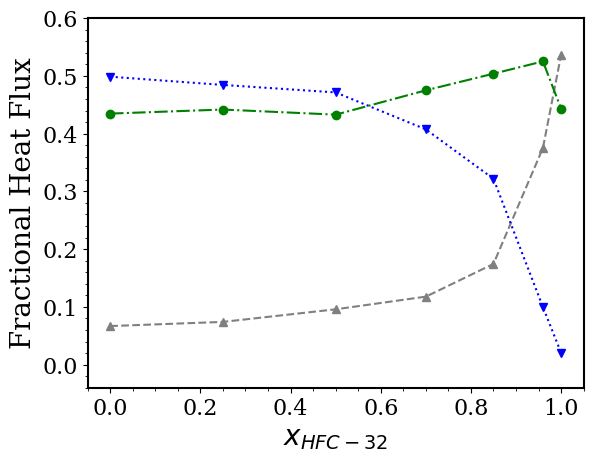

In [22]:
plt.rcParams.update({
    "text.usetex": False, # Set to True if you have LaTeX installed
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 1.5
})


fig, ax = plt.subplots()

#frac_bond, frac_angle, frac_dihed, frac_vdwCoul, frac_convec, fin_total, fin_total_ce, fin_imposed 

plt.plot(MD_TC_comp_R32, HFD_convec_R32, ls='--', marker='^', color='gray')
plt.plot(MD_TC_comp_R32, HFD_bonded_R32, ls=':', marker='v', color='blue')
plt.plot(MD_TC_comp_R32, HFD_nonbonded_R32, ls='-.', marker='o', color='green')

plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
ax.minorticks_on()
plt.ylim(-0.04, 0.6)
plt.ylabel( "Fractional Heat Flux", fontsize=20)
plt.xlabel(r'$x_{HFC-32}$', fontsize=20)
#plt.legend(["Molecular Transport", "Bonded interactions", "vdW and Coulombic"], bbox_to_anchor=(-0.1, 1.04, 1.2, 0.2), loc="lower left", mode="expand", ncol=3, fontsize=10)

plt.savefig("R32_emimtfsi_HFD", dpi=500, bbox_inches='tight')


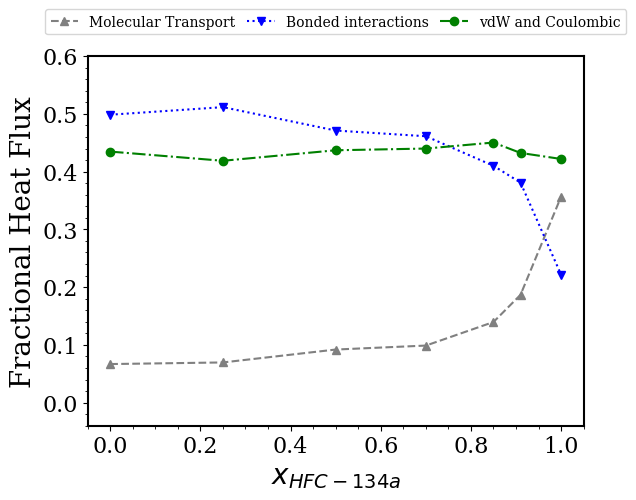

In [23]:
plt.rcParams.update({
    "text.usetex": False, # Set to True if you have LaTeX installed
    "font.family": "serif",
    "font.size": 12,
    "axes.linewidth": 1.5
})


fig, ax = plt.subplots()

#frac_bond, frac_angle, frac_dihed, frac_vdwCoul, frac_convec, fin_total, fin_total_ce, fin_imposed 

plt.plot(MD_TC_comp_R134a, HFD_convec_R134a, ls='--', marker='^', color='gray')
plt.plot(MD_TC_comp_R134a, HFD_bonded_R134a, ls=':', marker='v', color='blue')
plt.plot(MD_TC_comp_R134a, HFD_nonbonded_R134a, ls='-.', marker='o', color='green')

plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
ax.minorticks_on()
plt.ylim(-0.04, 0.6)
plt.ylabel( "Fractional Heat Flux", fontsize=20)
plt.xlabel(r'$x_{HFC-134a}$', fontsize=20)
plt.legend(["Molecular Transport", "Bonded interactions", "vdW and Coulombic"], \
          bbox_to_anchor=(-0.1, 1.04, 1.2, 0.2), loc="lower left", mode="expand", ncol=3, fontsize=10)

plt.savefig("R134a_emimtfsi_HFD", dpi=500, bbox_inches='tight')


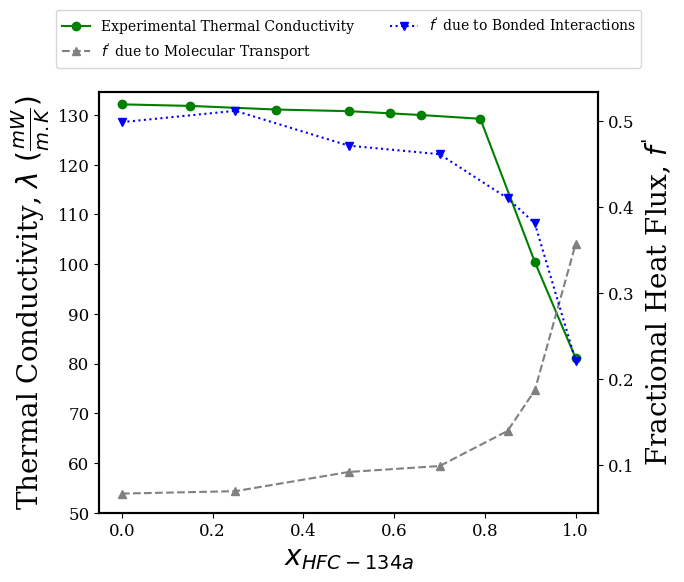

In [24]:

# Left-axis data
# x1 = np.array([280, 300, 320, 340])
# y1 = np.array([0.12, 0.13, 0.15, 0.16])

# # Right-axis data (Dataset 1)
# x2 = np.array([285, 295, 315, 335, 355, 375])
# y2 = np.array([995, 990, 978, 965, 952, 940])

# # Right-axis data (Dataset 2)
# y3 = np.array([1002, 997, 985, 972, 960, 948])

fig, ax1 = plt.subplots(figsize=(7, 6))

# Left y-axis
line1, = ax1.plot(Exp_TC_comp_R134a, Exp_TC_R134a, 'o-', color='green', label='Experimental Thermal Conductivity')
ax1.set_xlabel(r'$x_{HFC-134a}$', fontsize=20)
ax1.set_ylabel(r'Thermal Conductivity, $\lambda$' ' ' r'$(\frac{mW}{m.K})$', fontsize=20)
ax1.set_ylim(bottom=50)

# Right y-axis
ax2 = ax1.twinx()

line2, = ax2.plot(MD_TC_comp_R134a, HFD_convec_R134a, ls='--', marker='^', color='gray' , label="$f^'$ due to Molecular Transport")
line3, = ax2.plot(MD_TC_comp_R134a, HFD_bonded_R134a, ls=':', marker='v', color='blue' , label="$f^'$ due to Bonded Interactions")

ax2.set_ylabel( "Fractional Heat Flux, $f^'$", fontsize=20)

# Combined legend
lines = [line1, line2, line3]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, bbox_to_anchor=(-0.1, 1.04, 1.2, 0.2), loc="lower left", mode="expand", ncol=2, fontsize=10)

# Set x limits to include all data
# xmin = min(x1.min(), x2.min())
# xmax = max(x1.max(), x2.max())
# ax1.set_xlim(xmin, xmax)

plt.tight_layout()
plt.show()

In [25]:

exp_KT_data_file = pd.read_excel("KT_plot_data.xlsx")
exp_ionicity_data_file = pd.read_excel("Ionicity_plot_data.xlsx")


In [26]:

exp_KT_data_file.head()


,xHFC,π*,u(x),u(π*)
0,0.000,0.984200,0.00,0.05
1,0.190,0.946603,0.05,0.05
2,0.348,0.946603,0.05,0.05
3,0.470,0.946603,0.05,0.05
4,0.645,0.899000,0.05,0.05


In [27]:

exp_ionicity_data_file.head()


,xHFC,ʌ/ʌNE,u(xHFC),u(ʌ/ʌNE)
0,0.00,0.807087,0.000,0.000000
1,0.22,0.498948,0.011,0.049895
2,0.29,0.444416,0.015,0.044442
3,0.36,0.460266,0.018,0.046027
4,0.41,0.439334,0.021,0.043933


In [28]:
exp_KT_data_file["xHFC"]

0    0.000
1    0.190
2    0.348
3    0.470
4    0.645
5    0.822
6    0.860
7    1.000
Name: xHFC, dtype: float64

In [29]:
exp_KT_data_file["π*"]

0    0.984200
1    0.946603
2    0.946603
3    0.946603
4    0.899000
5    0.890000
6    0.870000
7    0.549000
Name: π*, dtype: float64

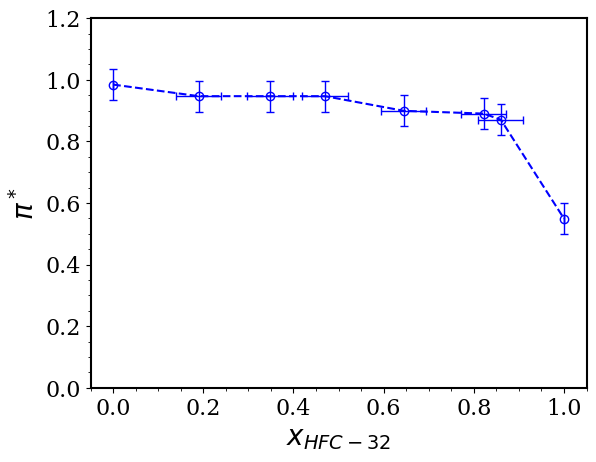

In [30]:

fig, ax = plt.subplots()

ax.errorbar(exp_KT_data_file["xHFC"], exp_KT_data_file["π*"], xerr = exp_KT_data_file["u(x)"], yerr = exp_KT_data_file["u(π*)"], fmt='o--', ecolor = 'blue',color='blue',  markerfacecolor='none', markeredgecolor='blue', elinewidth=1, label = 'Experiment', capsize=3) #fmt='o',
#ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", ncol=3, fontsize=12.5)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
ax.minorticks_on()
plt.ylim(0, 1.2)
plt.xlabel(r'$x_{HFC-32}$', fontsize=20)
plt.ylabel(r'$\pi^*$', fontsize=20)

plt.savefig("Exp_kamlet_taft_R32_New", dpi=300, bbox_inches='tight')


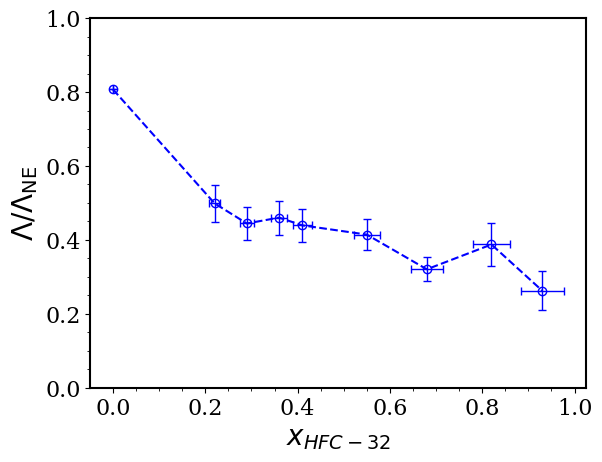

In [31]:

fig, ax = plt.subplots()

ax.errorbar(exp_ionicity_data_file["xHFC"], exp_ionicity_data_file["ʌ/ʌNE"], xerr = exp_ionicity_data_file["u(xHFC)"], yerr = exp_ionicity_data_file["u(ʌ/ʌNE)"], fmt='o--', ecolor = 'blue',color='blue',  markerfacecolor='none', markeredgecolor='blue', elinewidth=1, label = 'Experiment', capsize=3) #fmt='o',
#ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand", ncol=3, fontsize=12.5)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
ax.minorticks_on()
plt.ylim(0, 1.0)
plt.xlabel(r'$x_{HFC-32}$', fontsize=20)
plt.ylabel(r'$\Lambda/\Lambda_{\mathrm{NE}}$', fontsize=20)

plt.savefig("Exp_ionicity_R32_New", dpi=300, bbox_inches='tight')
